# Random Forest para clasificar anemia infantil

## 1. Carga de datos

CSV del grupo elaborado con datos ENDES 2020–2025. La variable ANEMIA indica 0 para ausencia de anemia y 1 para presencia.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, auc, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

archivo = Path("DATASET_LIMPIO_ANEMIA.csv")
if not archivo.is_file():
    archivo = Path.home() / "Downloads" / archivo

datos = pd.read_csv(archivo)
X = datos.drop(columns="ANEMIA")
y = datos["ANEMIA"]

print(f"Registros: {len(datos):,} | Predictores: {X.shape[1]}")
print(y.value_counts().rename(index={0: "Sin anemia", 1: "Con anemia"}).to_string())

Registros: 99,472 | Predictores: 25
ANEMIA
Sin anemia    65765
Con anemia    33707


## 2. Preparación de datos

División estratificada de 80 % para entrenamiento y 20 % para prueba. La codificación de categorías se ajusta en entrenamiento. El código −1 de anemia materna durante el embarazo se conserva como categoría.

In [2]:
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

categoricas = [
    "anemia_materna_embarazo", "desparasitacion", "diarrea_reciente",
    "fiebre_reciente", "nivel_educativo_madre", "quintil_riqueza",
    "area_residencia", "sexo_nino", "anemia_materna_actual", "nivel_pobreza",
    "departamento",
]

codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
preparacion = ColumnTransformer(
    [("categorias", codificador, categoricas)],
    remainder="passthrough",
)

print(f"Entrenamiento: {len(X_entrenamiento):,} registros")
print(f"Prueba: {len(X_prueba):,} registros")

Entrenamiento: 79,577 registros
Prueba: 19,895 registros


## 3. Entrenamiento

In [3]:
bosque = RandomForestClassifier(
    n_estimators=100, max_depth=12, random_state=42, n_jobs=-1
)
modelo = make_pipeline(preparacion, bosque)
modelo.fit(X_entrenamiento, y_entrenamiento)

probabilidad = modelo.predict_proba(X_prueba)[:, 1]
prediccion = (probabilidad >= 0.5).astype(int)

## 4. Evaluación

El umbral es 0,5. El recall mide la proporción de casos de anemia que detectó el modelo.

,Prueba (%)
Exactitud,72.61
Precisión de anemia,64.60
Recall de anemia,42.39
F1 de anemia,51.19
ROC-AUC,75.12
PR-AUC,61.00


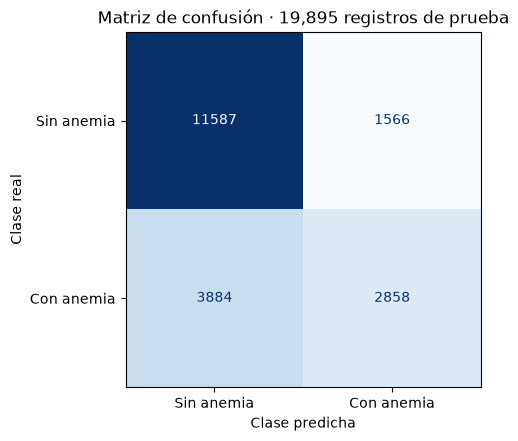

In [4]:
precision_curva, recall_curva, _ = precision_recall_curve(y_prueba, probabilidad)
metricas = pd.Series({
    "Exactitud": accuracy_score(y_prueba, prediccion),
    "Precisión de anemia": precision_score(y_prueba, prediccion, zero_division=0),
    "Recall de anemia": recall_score(y_prueba, prediccion),
    "F1 de anemia": f1_score(y_prueba, prediccion),
    "ROC-AUC": roc_auc_score(y_prueba, probabilidad),
    "PR-AUC": auc(recall_curva, precision_curva),
}, name="Prueba")

display((metricas * 100).round(2).to_frame("Prueba (%)"))

matriz = confusion_matrix(y_prueba, prediccion, labels=[0, 1])
_, eje = plt.subplots(figsize=(5.6, 4.3), layout="constrained")
ConfusionMatrixDisplay(
    matriz, display_labels=["Sin anemia", "Con anemia"]
).plot(ax=eje, cmap="Blues", colorbar=False, values_format="d")
eje.set(
    title=f"Matriz de confusión · {len(y_prueba):,} registros de prueba",
    xlabel="Clase predicha", ylabel="Clase real"
)
plt.show()

## 5. Resultados

In [5]:
_, falsos_positivos, falsos_negativos, verdaderos_positivos = matriz.ravel()
casos_reales = verdaderos_positivos + falsos_negativos

print(f"Casos detectados: {verdaderos_positivos:,} de {casos_reales:,}.")
print(f"Falsos negativos: {falsos_negativos:,}. Falsos positivos: {falsos_positivos:,}.")

Casos detectados: 2,858 de 6,742.
Falsos negativos: 3,884. Falsos positivos: 1,566.
